## ARM KAZR Cloud Persistence Project: Observation Validation

**Alec Blevins**
**STA 496 - Fall 2026**

### Purpose
This notebook investigates the quality-control and instrument-status information contained in the ARM KAZRARSCL interim dataset. 

The goal is to determine which observations are suitable for subsequent cloud-state analysis and feature engineering. The results of this notebook will be used to define the QC rules implemented in the project's preprocessing pipeline. 

This notebook does not modify the KAZR observations. Instead, it examines ARM-provided quality indicators, missingness, clutter, and instrument avilability before those conditions are incorporated into the processing pipeline. 

### Notebook Structure

1. Interim Dataset
2. Dataset Structure
3. Instrument Availability
4. Reflectivity QC
5. Doppler Velocity QC
6. Spectral Width QC
7. Clutter Flags
8. Interaction Between QC Conditions
9. Missingness and Temporal Gaps
10. Preliminary QC Rules
11. QC Summary Across 2024
12. Conclusions / Next Step

### Imports

In [15]:
#Library Imports
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt


#Install project path 
PROJECT_ROOT = Path.cwd().parent

INTERIM_DATA_DIR = (
    PROJECT_ROOT
    / "ARM_DATA"
    / "2024-2025"
    / "interim"
    / "sgparsclkazr1kolliasC1.c0"
)

interim_files = sorted(INTERIM_DATA_DIR.glob("*.nc"))

print(f"Number of interim files: {len(interim_files)}")
print(f"First file: {interim_files[0].name}")
print(f"Last file:  {interim_files[-1].name}")

#Open one representative interim file
sample_interim = xr.open_dataset(interim_files[0])
print(sample_interim)

Number of interim files: 367
First file: kazr_20240101.nc
Last file:  kazr_20250101.nc
<xarray.Dataset> Size: 517MB
Dimensions:                        (time: 21600, height: 596, layer: 10)
Coordinates:
  * time                           (time) datetime64[ns] 173kB 2024-01-01 ......
  * height                         (height) float32 2kB 160.0 ... 1.801e+04
  * layer                          (layer) int32 40B 0 1 2 3 4 5 6 7 8 9
Data variables: (12/16)
    reflectivity_best_estimate     (time, height) float32 51MB ...
    mean_doppler_velocity          (time, height) float32 51MB ...
    spectral_width                 (time, height) float32 51MB ...
    signal_to_noise_ratio          (time, height) float32 51MB ...
    qc_reflectivity_best_estimate  (time, height) int32 51MB ...
    qc_mean_doppler_velocity       (time, height) int32 51MB ...
    ...                             ...
    cloud_layer_top_height         (time, layer) float32 864kB ...
    cloud_mask_mplzwang            (tim

Firstly, lets confirm dimensions, then specifically identify the QC-related variables. 

The purpose of this investigation is to distinguish among three different situations: 
1. an instrument is unavailable; 
2. a particular time-height measurement is invalid or missing; and
3. a measurement is simply absent because the radar did not detect a hydrometeor return. 

In [4]:
print("Dimensions:")
for dim, size in sample_interim.sizes.items():
    print(f"  {dim}: {size}")

print("\nSelected variables:")
for var in sample_interim.data_vars:
    print(f"  {var}")

Dimensions:
  time: 21600
  height: 596
  layer: 10

Selected variables:
  reflectivity_best_estimate
  mean_doppler_velocity
  spectral_width
  signal_to_noise_ratio
  qc_reflectivity_best_estimate
  qc_mean_doppler_velocity
  qc_spectral_width
  reflectivity_clutter_flag
  cloud_base_best_estimate
  cloud_layer_base_height
  cloud_layer_top_height
  cloud_mask_mplzwang
  radar_first_top
  instrument_availability_flag
  radar_mode_flag
  cloud_source_flag


In [6]:
QC_VARIABLES = [
    "instrument_availability_flag",
    "qc_reflectivity_best_estimate",
    "qc_mean_doppler_velocity",
    "qc_spectral_width",
    "reflectivity_clutter_flag",
    "cloud_mask_mplzwang",
]

for var in QC_VARIABLES:
    print(var)

instrument_availability_flag
qc_reflectivity_best_estimate
qc_mean_doppler_velocity
qc_spectral_width
reflectivity_clutter_flag
cloud_mask_mplzwang


### Instrument Availability

In [8]:
print(sample_interim["instrument_availability_flag"].attrs)

{'long_name': 'Indicates which instruments have data available', 'units': 'unitless', 'flag_masks': array([ 1,  2,  4,  8, 16], dtype=int16), 'flag_meanings': 'KAZR MPL Ceilometer MWR rain_gauge', 'bit_1_description': 'KAZR', 'bit_2_description': 'MPL', 'bit_3_description': 'Ceilometer', 'bit_4_description': 'MWR', 'bit_5_description': 'rain gauge'}


In [10]:
values, counts = np.unique(
    sample_interim["instrument_availability_flag"].values,
    return_counts=True
)

availability_summary = pd.DataFrame({
    "value": values,
    "count": counts,
    "fraction": counts / counts.sum(),
})

availability_summary

,value,count,fraction
0,31,21600,1.0


### Interpreting the availability flag

The availability value is a **bit mask**, not a single categorical label. Each bit corresponds to a different instrument: 

- `1` = KAZR
- `2` = MPL
- `4` = Ceilometer
- `8` = MWR
- `16` = rain gauge

Here, the observed value on this representative day is `31`, as [31 = 1 + 2 + 4 + 8 + 16]

All five listed instrument are reported as available for all 21,600 timestamps on this day. 

for the later QC pipeline, the minimum instrument requirement should be based on the **KAZR bit** becuase KAZR is the primary measurement source for this project. We should retain the complete bit mask rather than requiring all five instruments to be available. 

### Reflectivity QC

In [12]:
var = "qc_reflectivity_best_estimate"

print(sample_interim[var].attrs)

{'long_name': 'Quality check results on field: Best-estimate reflectivity', 'units': 'unitless', 'description': 'This field contains bit packed integer values, where each bit represents a QC test on the data. Non-zero bits indicate the QC condition given in the description for those bits; a value of 0 (no bits set) indicates the data has not failed any QC tests.', 'flag_method': 'bit', 'bit_1_description': 'Value is less than the valid_min.', 'bit_1_assessment': 'Bad', 'bit_2_description': 'Value is greater than the valid_max.', 'bit_2_assessment': 'Bad', 'bit_3_description': 'Data value not available in input file, data value has been set to missing_value.', 'bit_3_assessment': 'Bad'}


In [14]:
values, counts = np.unique(
    sample_interim[var].values,
    return_counts=True
)

reflectivity_qc_summary = pd.DataFrame({
    "value": values,
    "count": counts,
    "fraction": counts / counts.sum(),
})

reflectivity_qc_summary

,value,count,fraction
0,0,498254,0.038704
1,4,12375346,0.961296


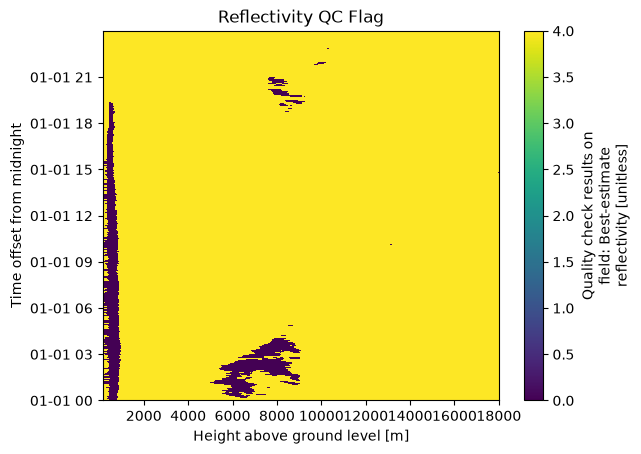

In [16]:
sample_interim[var].plot()
plt.title("Reflectivity QC Flag")
plt.show()

### Interpreting the reflectivity QC result 

Here, the QC field has only two observed values: 
- `0`: 498,254 time-height cells
- `4`: 12,375,346 time-height cells

The metadata explains that the QC field is **bit packed**. A value of `4` means that bit 3 is set: the input data value was unavailable. 

Bits 1 and 2 correspond to values ooutside the valid minimum or maximum. Neither of those flags appears on this representative day. 

Therefore, we should not interpret the 96.13% of value `4` as a broken radar. Instead, these are time-height locations where a reflectivity value was not available. 

In other words, "96% of the 12.87 million time-height locations do not contain any available reflectivity measurement."

### Doppler Velocity QC

In [18]:
var = "qc_mean_doppler_velocity"

print(sample_interim[var].attrs)

values, counts = np.unique(
    sample_interim[var].values,
    return_counts=True
)

pd.DataFrame({
    "value": values,
    "count": counts,
    "fraction": counts / counts.sum(),
})

{'long_name': 'Quality check results on field: Mean Doppler velocity', 'units': 'unitless', 'description': 'This field contains bit packed integer values, where each bit represents a QC test on the data. Non-zero bits indicate the QC condition given in the description for those bits; a value of 0 (no bits set) indicates the data has not failed any QC tests.', 'flag_method': 'bit', 'bit_1_description': 'Value is less than the valid_min.', 'bit_1_assessment': 'Bad', 'bit_2_description': 'Value is greater than the valid_max.', 'bit_2_assessment': 'Bad', 'bit_3_description': 'Data value not available in input file, data value has been set to missing_value.', 'bit_3_assessment': 'Bad'}


,value,count,fraction
0,0,503529,0.039113
1,4,12370071,0.960887


### Interpreting Doppler Velocity QC

The Doppler QC field has the same basic pattern as reflectivity: 
- `0`: 503,529 cells
- `4`: 12,370,071 cells

Again, value `4` represents the third QC bit: the input value was unavailable. 

### Spectral Width QC

In [19]:
var = "qc_spectral_width"

print(sample_interim[var].attrs)

values, counts = np.unique(
    sample_interim[var].values,
    return_counts=True
)

pd.DataFrame({
    "value": values,
    "count": counts,
    "fraction": counts / counts.sum(),
})

{'long_name': 'Quality check results on field: Spectral width', 'units': 'unitless', 'description': 'This field contains bit packed integer values, where each bit represents a QC test on the data. Non-zero bits indicate the QC condition given in the description for those bits; a value of 0 (no bits set) indicates the data has not failed any QC tests.', 'flag_method': 'bit', 'bit_1_description': 'Value is less than the valid_min.', 'bit_1_assessment': 'Bad', 'bit_2_description': 'Value is greater than the valid_max.', 'bit_2_assessment': 'Bad', 'bit_3_description': 'Data value not available in input file, data value has been set to missing_value.', 'bit_3_assessment': 'Bad'}


,value,count,fraction
0,0,503529,0.039113
1,4,12370071,0.960887


### Interpreting Spectral-width QC

Spectral width has the same counts as Doppler velocity: 
- `0`: 503,529 cells
- `4`: 12,370,071 cells

Thus, on this representative day, the QC system is not identifying a large number of out-of-range spectral-width values. Instead, most time-height cells simply do not contain an available measurement. 

This reinforces the idea that the radar measurements are **sparse in the vertical domain**. A QC pipeline should therefore avoid treating the absence of a measurement at most heights as a data issue. 

### Clutter Investigation

In [20]:
print(sample_interim["reflectivity_clutter_flag"].attrs)

{'long_name': 'Reflectivity clutter flag', 'units': 'unitless', 'flag_values': array([ 0,  1,  2,  3,  9, 10], dtype=int16), 'flag_meanings': 'No_significant_detection Hydrometeor-only_detection Both_hydrometeor_and_clutter_detection Clutter-only_detection Bad_data Missing_data', 'flag_0_description': 'No significant detection', 'flag_1_description': 'Hydrometeor-only detection', 'flag_2_description': 'Both hydrometeor and clutter detection', 'flag_3_description': 'Clutter-only detection', 'flag_9_description': 'Bad data', 'flag_10_description': 'Missing data'}


In [21]:
values, counts = np.unique(
    sample_interim["reflectivity_clutter_flag"].values,
    return_counts=True
)

clutter_summary = pd.DataFrame({
    "value": values,
    "count": counts,
    "fraction": counts / counts.sum(),
})

clutter_summary

,value,count,fraction
0,0,12370071,0.960887
1,1,498254,0.038704
2,3,5275,0.000410


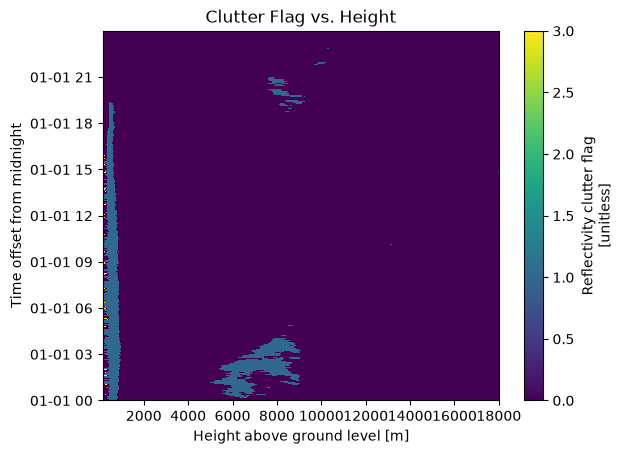

In [23]:
var = "reflectivity_clutter_flag"
sample_interim[var].plot()
plt.title("Clutter Flag vs. Height")
plt.show()

### Interpreting Clutter Results

The clutter flag is different from the QC fields becuase it describes **what kind of radar return was detected**. 

On this representative day, the observed values are: 

| Flag | Meaning | Fraction |
|---:|---|---:|
| 0 | No significant detection | 96.09% |
| 1 | Hydrometeor-only detection | 3.87% |
| 2 | Hydrometeor + clutter | 0% observed |
| 3 | Clutter-only detection | 0.041% |
| 9 | Bad data | 0% observed |
| 10 | Missing data | 0% observed |

Note that the 498,254 reflectivity cells with QC value `0` exactly match with 498,254 cells with clutter flag `1` (hydrometeor-only detection). 

There are also 5,275 cells markeed as clutter-only. These may account for the small difference between the number of non-missing reflectivity cells and the number of non-missing Doppler/spectral-width cells. 

The plot shows that clutter is concentrated near the lower part of the radar profile. This means clutter should be treated as a time-height measurement-level issue. 


### Cloud Mask & Cloud Detection

In [25]:
print(sample_interim["cloud_mask_mplzwang"].attrs)

{'long_name': 'Cloud mask from 30smpl1zwang', 'units': 'unitless', 'flag_values': array([0, 1, 2], dtype=int16), 'flag_meanings': 'clear cloudy mask_not_used_to_determine_cloud_boundaries_below_3km', 'flag_0_description': 'clear', 'flag_1_description': 'cloudy', 'flag_2_description': 'Mask not used to determine cloud boundaries below 3km', 'comment': 'Cloud mask indeterminate below 500 m'}


In [26]:
values, counts = np.unique(
    sample_interim["cloud_mask_mplzwang"].values,
    return_counts=True
)

cloud_mask_summary = pd.DataFrame({
    "value": values,
    "count": counts,
    "fraction": counts / counts.sum(),
})

cloud_mask_summary

,value,count,fraction
0,0.0,12535399,0.973729
1,1.0,99446,0.007725
2,2.0,1155,0.000090
3,NaN,237600,0.018456


### Interpreting Cloud-Mask

The cloud mask is also a time-height field. 

On this representative day: 
- 97.37% of time-height cells are `0` = clear
- 0.77% are `1` = cloudy
- 0.009% are `2`
- 1.85% are missing

These values should not be interpreted as "only 0.777% of the day was cloudy." They describe the fraction of the entire vertical grid occupied by each mask value. 

The value `2` is also not a cloudy flag. It means that this cloud mask was not used to determine cloud boundaries below 3 km. The metadata also notes that the mask is indeterminate below 500 m. 

Therefore, the cloud mask is useful as a supporting cloud-detection variable, but it should not yet become the sole definition of cloud presence. 

### An aside: Cloud-Mask Detection & Cloud-Layer Detection

Our project already has another way to define instantaneous cloud presence: the ARM cloud-layer product. We can compare the two definitions without assuming they must agree perfectly. 


In [ ]:
#Negative values are used for clear-sky states, only pick nonnegative. 
cloud_from_layers = (
    sample_interim["cloud_layer_base_height"] >= 0 # Check if there is any cloud layer present
).any(dim="layer")

#time x height field, 1 = cloudy
cloud_from_mask = (
    sample_interim["cloud_mask_mplzwang"] == 1 # Check if the cloud mask indicates a cloud at any height
).any(dim="height")

comparison = pd.crosstab( # Create a cross-tabulation to compare cloud detection from layers and mask
    cloud_from_layers.values,
    cloud_from_mask.values,
    rownames=["Cloud layer detected"],
    colnames=["Cloud mask detected"],
    margins=True,
)

comparison

Cloud mask detected,False,True,All
Cloud layer detected,,,
False,779,1,780
True,17603,3217,20820
All,18382,3218,21600


Considering the crosstab, we have 779 timestamps where the two methods agree that no cloud was detected. 

Looking at the top-right: 1, the cloud mask finds cloud somewhere in the vertical profile, whereas the cloud-layer product reports no layer. With only 1 timestamp, the mask almost never finds cloud in isolation from the layer project. 

Then, 17,603: the cloud-layer product says there is a cloud layer, but the mask does not contain a `1` at any height. Lastly, there are 3,217 timestamps where both methods identify cloud. 

Thus, we can see about 15.5% of the layer-detected timestamps also have a mask value of 1 somewhere. Furthermore, essentially every timestamp where the mask detects cloud also has a cloud layer. 

This disagreement is not an error, as they are derived from different retrieval information, and the cloud-mask metadata identifies locations where the mask is not used to determine boundaries. This comparason is therefore diagnostic. 

### QC Interaction

In [30]:
#Here, we will create a few boolean conditions based on QC conclusions. 

# Extract instrument availability and QC flags from the sample_interim dataset.
availability = sample_interim["instrument_availability_flag"].astype("int64")
kazr_available = (availability & 1) != 0

# Extract QC flags for reflectivity, Doppler velocity, and spectral width.
refl_qc = sample_interim["qc_reflectivity_best_estimate"].astype("int64")
doppler_qc = sample_interim["qc_mean_doppler_velocity"].astype("int64")
width_qc = sample_interim["qc_spectral_width"].astype("int64")

# Extract the clutter flag for reflectivity.
clutter = sample_interim["reflectivity_clutter_flag"].astype("int64")

# A value of 0 means no QC test failed.
reflectivity_qc_pass = refl_qc == 0
doppler_qc_pass = doppler_qc == 0
width_qc_pass = width_qc == 0

# The missing-data condition is bit 3, corresponding to mask 4.
reflectivity_missing = (refl_qc & 4) != 0
doppler_missing = (doppler_qc & 4) != 0
width_missing = (width_qc & 4) != 0

# Clean hydrometeor return for reflectivity features.
clean_reflectivity = reflectivity_qc_pass & (clutter == 1)

interaction_summary = pd.DataFrame({
    "condition": [
        "KAZR available",
        "Reflectivity QC pass",
        "Reflectivity marked missing",
        "Clean hydrometeor reflectivity",
        "Doppler QC pass",
        "Doppler marked missing",
        "Spectral width QC pass",
        "Spectral width marked missing",
        "Clutter-only",
    ],
    "fraction": [
        float(kazr_available.mean()),
        float(reflectivity_qc_pass.mean()),
        float(reflectivity_missing.mean()),
        float(clean_reflectivity.mean()),
        float(doppler_qc_pass.mean()),
        float(doppler_missing.mean()),
        float(width_qc_pass.mean()),
        float(width_missing.mean()),
        float((clutter == 3).mean()),
    ],
})

interaction_summary



,condition,fraction
0,KAZR available,1.000000
1,Reflectivity QC pass,0.038704
2,Reflectivity marked missing,0.961296
3,Clean hydrometeor reflectivity,0.038704
4,Doppler QC pass,0.039113
5,Doppler marked missing,0.960887
6,Spectral width QC pass,0.039113
7,Spectral width marked missing,0.960887
8,Clutter-only,0.000410


### Interpreting The QC Interaction 

Looking at the representative sample, we can see that instrument availability and measurement validity represent different aspects of the KAZR observations. Here, KAZR was available for 100% of timestamps, while only about 3.9% of time-height locations contained reflectivity, Doppler velocity, or spectral-width measurements that passed their respective QC tests. Its important to note that this reflects the absence of significant radar returns at most heights rather than instrument failure. 

We can also see the reflectivity QC-passing fraction also matched the hydrometeor-only detection fraction, while the small number of additional Doppler and spectral-width QC-passing locations corresponded to clutter-only detections. 

Therefore, QC should be applied at the individual time-height level when evaluating radar measurements, rather than treating missing measurements as unusable timestamps. 

### Missingness and Temporal Gaps

In [28]:
variables_to_check = [
    "reflectivity_best_estimate",
    "mean_doppler_velocity",
    "spectral_width",
    "cloud_layer_base_height",
    "cloud_layer_top_height",
]

missing_summary = []

for var in variables_to_check:
    missing_summary.append({
        "variable": var,
        "missing_count": int(sample_interim[var].isnull().sum()),
        "missing_fraction": float(sample_interim[var].isnull().mean()),
    })

missing_summary = pd.DataFrame(missing_summary)

missing_summary

,variable,missing_count,missing_fraction
0,reflectivity_best_estimate,12375346,0.961296
1,mean_doppler_velocity,12370071,0.960887
2,spectral_width,12370071,0.960887
3,cloud_layer_base_height,0,0.000000
4,cloud_layer_top_height,0,0.000000


### Important: NaN missingness is not the same as clear sky

Here, the zero missingness reported for the cloud-layer base and top variables does not mean that a cloud layer exists at every timestamp. 

The ARM cloud-layer fields use encoded values to represent clear-sky conditions. Therefore, we need to inspect the actual values rather than relying only on `isnull()`. 

In [31]:
for var in [
    "cloud_base_best_estimate",
    "cloud_layer_base_height",
    "cloud_layer_top_height",
]:
    print(f"\n{var}")
    print(sample_interim[var].attrs)

    values = np.unique(sample_interim[var].values)
    print("Smallest observed values:", values[:10])
    print("Largest observed values:", values[-10:])


cloud_base_best_estimate
{'long_name': 'Cloud base best estimate, based on ceilometer and micropulse lidar', 'units': 'm', 'valid_range': array([    0., 25000.], dtype=float32), 'flag_values': array([-2., -1.], dtype=float32), 'flag_meanings': 'possible_clear_sky clear_sky', 'comment': '-2. Possible clear sky (No MPL observations available, Ceilometer obscured, but no cloud detected), -1. Clear sky, >= 0. Valid cloud base height'}
Smallest observed values: [ -1. 360. 370. 380. 390. 400. 410. 420. 430. 440.]
Largest observed values: [10125.582  10155.562  10185.541  10215.5205 10245.501  10275.48
 10305.46   10335.439  10365.419  10395.399 ]

cloud_layer_base_height
{'long_name': 'Base height of hydrometeor layers for up to 10 layers, based on combined radar and micropulse lidar observations', 'units': 'm', 'valid_range': array([    0., 25000.], dtype=float32), 'flag_values': np.float32(-1.0), 'flag_meanings': 'clear_sky'}
Smallest observed values: [ -1. 160. 250. 280. 310. 340. 370. 4

In [32]:
layer_base = sample_interim["cloud_layer_base_height"]

cloudy_from_layers = (
    layer_base >= 0
).any(dim="layer")

layer_summary = pd.DataFrame({
    "metric": [
        "Total timestamps",
        "Cloudy timestamps",
        "Clear timestamps",
        "Cloud fraction",
    ],
    "value": [
        cloudy_from_layers.size,
        int(cloudy_from_layers.sum()),
        int((~cloudy_from_layers).sum()),
        float(cloudy_from_layers.mean()),
    ],
})

layer_summary

,metric,value
0,Total timestamps,21600.000000
1,Cloudy timestamps,20820.000000
2,Clear timestamps,780.000000
3,Cloud fraction,0.963889


`cloud_base_best_estimate` is a single cloud-base height for each timestamp, based on the ceilometer and micropulse lidar. Its metadata tells us: 
- `-2` = possible clear sky
- `-1` = clear sky
- `>=0` = valid cloud-base height

The cloud-height variables do not use `NaN` to represent clear-sky conditions. Instead, ARM explicitly encodes clear sky using sentinel values. For `cloud_layer_base_height` and `cloud_layer_top_height`, `-1` indicates clear sky and nonnegative values represent detected hydrometeor layers.

Therefore, the absence of a cloud should not be interpreted as missing data. This distinction is important for constructing the cloud-state target: clear observations are valid states that should be retained, whereas actual `NaN` values should be treated as unavailable observations. 

### Temporal Spacing and Gaps

A QC pipeline should identify missing time steps separately from missing measurements within otherwise valid time steps. 

In [33]:
time_index = pd.DatetimeIndex(sample_interim.time.values)

time_deltas = (
    time_index.to_series()
    .diff()
    .dt.total_seconds()
    .dropna()
)

print(f"Median time step: {time_deltas.median():.1f} seconds")
print(f"Minimum time step: {time_deltas.min():.1f} seconds")
print(f"Maximum time step: {time_deltas.max():.1f} seconds")
print(
    "Number of gaps larger than 4 seconds:",
    int((time_deltas > 4).sum())
)

gap_summary = time_deltas[time_deltas > 4]

gap_summary.head(20)

Median time step: 4.0 seconds
Minimum time step: 4.0 seconds
Maximum time step: 4.0 seconds
Number of gaps larger than 4 seconds: 0


Series([], dtype: float64)

For this representative file, we have a regular 4-second time grid with no substantial gaps, indicating that the time axis itself is complete. 

### Preliminary QC Rules

Based on the representative-day investigation, the following rules are reasonable provisional definitions. They should be checked against the complete 2024 dataset before being moved into `src/qc.py`. 

#### Time-level rule: 
A timestamp is instrument-valid when the KAZR bit is set in `instrument_availability_flag`: 

```python
kazr_available = (instrument_availability_flag & 1) != 0
```

The complete avilability bit mask should be retained because the other instruments may help explain the source of cloud-boundary information. 

#### Measurement-level rules
For radar measurements: 
- `QC == 0` means that the available ARM QC tests have passed. 
- `QC` with bit 3 set means that the input measurement is unavailable. Treat this as missing for that variable rather than deleting the timestamp. 
- Other non-zero QC bits indicate additional conditions that should be examined before use. 

#### Reflectivity/clutter rule
For reflectivity-derived features, a conservative preliminary clean-return definition is: 

```python
clean_reflectivity = (
    (qc_reflectivity_best_estimate == 0)
    & (reflectivity_clutter_flag == 1)
)
```

This keeps hydrometeor-only detections and excludes clutter-only or mixed clutter returns. 

#### Cloud-state rule
Cloud presence will continue to be based primarly on the ARM cloud-layer product: 

```python
cloudy = (
    cloud_layer_base_height >= 0
).any(dim="layer")
```

Clear-sky sentinel values are therefore treated as a cloud-state encoding, not as missing data. 

### QC Summary Across 2024 (Year Analysis)
The representative day was useful for understanding the variables, but the final QC rules should be validated across the entire study year. 

Note: The interim directory contains one additional file from January 1, 2025. That file will be excluded explicitly. 

In [34]:
ANALYSIS_YEAR = 2024

def get_interim_file_date(file):
    date_string = file.stem.replace("kazr_", "")
    return pd.to_datetime(date_string, format="%Y%m%d")

file_dates = pd.DatetimeIndex(
    [get_interim_file_date(file) for file in interim_files]
).normalize()

expected_dates = pd.date_range(
    f"{ANALYSIS_YEAR}-01-01",
    f"{ANALYSIS_YEAR}-12-31",
    freq="D",
)

analysis_files = [
    file for file in interim_files
    if get_interim_file_date(file).year == ANALYSIS_YEAR
]

analysis_dates = pd.DatetimeIndex(
    [get_interim_file_date(file) for file in analysis_files]
).normalize()

duplicate_dates = analysis_dates[analysis_dates.duplicated()]
missing_dates = expected_dates.difference(analysis_dates)
extra_dates = file_dates.difference(expected_dates)

print(f"Files in interim directory: {len(interim_files)}")
print(f"{ANALYSIS_YEAR} files included: {len(analysis_files)}")
print(f"Expected {ANALYSIS_YEAR} days: {len(expected_dates)}")
print(f"Missing {ANALYSIS_YEAR} dates: {len(missing_dates)}")
print(f"Duplicate {ANALYSIS_YEAR} dates: {len(duplicate_dates)}")
print(f"Files outside {ANALYSIS_YEAR}: {len(extra_dates)}")

if len(missing_dates):
    print("\nMissing dates:")
    print(missing_dates)

if len(duplicate_dates):
    print("\nDuplicate dates:")
    print(duplicate_dates)

if len(extra_dates):
    print("\nFiles outside the analysis year:")
    print(extra_dates)

Files in interim directory: 367
2024 files included: 366
Expected 2024 days: 366
Missing 2024 dates: 0
Duplicate 2024 dates: 0
Files outside 2024: 1

Files outside the analysis year:
DatetimeIndex(['2025-01-01'], dtype='datetime64[us]', freq='D')


In [35]:
def summarize_qc_day(file):
    '''Create a compact QC summary from one daily interim KAZR file.'''

    with xr.open_dataset(file) as ds:
        time_index = pd.DatetimeIndex(ds.time.values)

        # Compute time differences between consecutive timestamps.
        time_deltas = (
            time_index.to_series() #Return a pandas Series
            .diff() #Difference
            .dt.total_seconds() #Convert to total seconds
            .dropna() #Remove NaN values
        )

        #Then decode instrument availability.
        availability = (
            ds["instrument_availability_flag"]
            .values
            .astype(np.int64)
        )

        # KAZR is bit 1 / mask 1.
        kazr_available = (availability & 1) != 0 #Extract just KAZR availability

        # Extract the measurement QC flags
        refl_qc = (
            ds["qc_reflectivity_best_estimate"]
            .values
            .astype(np.int64)
        )
        doppler_qc = (
            ds["qc_mean_doppler_velocity"]
            .values
            .astype(np.int64)
        )
        width_qc = (
            ds["qc_spectral_width"]
            .values
            .astype(np.int64)
        )

        # Missing-data bit is bit 3 / mask 4.
        refl_missing = (refl_qc & 4) != 0 #Identify missing measurements, extracting bit 3
        doppler_missing = (doppler_qc & 4) != 0
        width_missing = (width_qc & 4) != 0

        #Then identify range-failure bits, which are bits 1 and 2 / masks 1 and 2.
        #Here, basically asking "was this reflectivity measurement outside the valid range?"
        refl_range_failure = (
            ((refl_qc & 1) != 0) #below valid minimum? 
            | ((refl_qc & 2) != 0) #above valid maximum? 
        )
        doppler_range_failure = (
            ((doppler_qc & 1) != 0)
            | ((doppler_qc & 2) != 0)
        )
        width_range_failure = (
            ((width_qc & 1) != 0)
            | ((width_qc & 2) != 0)
        )

        #Then extract the clutter classification flag.
        clutter = (
            ds["reflectivity_clutter_flag"]
            .values
            .astype(np.int64)
        )

        clean_reflectivity = ( #Here, we can define "clean reflectivity"
            (refl_qc == 0) #No QC bits are set
            & (clutter == 1) #AND the clutter classifier says hydrometeor-only rather than clutter. 
        )

        # Cloud-state indicator from layer boundaries
        cloudy = (
            ds["cloud_layer_base_height"] >= 0
        ).any(dim="layer").values #Is at least one of the 10 layers cloudy?

        return {
            "date": get_interim_file_date(file).date(), #Date
            "n_time": len(time_index), #Number of timestamps 
            "median_timestep_seconds": float(time_deltas.median()), #Typical time spacing
            "max_timestep_seconds": float(time_deltas.max()), #Largest time space
            "n_time_gaps_gt_4s": int((time_deltas > 4).sum()), #Number of time gaps greater than 4 seconds
            "kazr_available_fraction": float(kazr_available.mean()), #Fraction of timestamps where KAZR data is available
            "reflectivity_missing_fraction": float(refl_missing.mean()), #Fraction of reflectivity measurements that are missing
            "reflectivity_range_failure_fraction": float(
                refl_range_failure.mean()
            ), #Fraction of reflectivity measurements that fail the range check
            "doppler_missing_fraction": float(doppler_missing.mean()), #Fraction of doppler marked missing
            "doppler_range_failure_fraction": float(
                doppler_range_failure.mean()
            ), #Fraction of doppler measurements that fail the range check
            "spectral_width_missing_fraction": float(
                width_missing.mean()
            ), #Fraction of spectral width measurements that are missing
            "spectral_width_range_failure_fraction": float(
                width_range_failure.mean()
            ), #Fraction of spectral width measurements that fail the range check
            "clean_reflectivity_fraction": float(
                clean_reflectivity.mean()
            ), #Fraction of reflectivity measurements that are clean (no QC issues and not clutter)
            "clutter_only_fraction": float(
                (clutter == 3).mean()
            ), #Fraction of measurements classified as clutter only
            "mixed_clutter_fraction": float(
                (clutter == 2).mean()
            ), #Fraction of measurements classified as mixed clutter
            "bad_clutter_flag_fraction": float(
                np.isin(clutter, [9, 10]).mean()
            ), #Fraction of measurements with bad clutter flags
            "cloudy_timestamp_fraction": float(
                cloudy.mean()
            ), #Fraction of timestamps with >= 1 detected cloud layer
        }


annual_qc = []

for i, file in enumerate(analysis_files, start=1): #Process whole year 
    print(f"[{i:03d}/{len(analysis_files):03d}] {file.name}")
    annual_qc.append(summarize_qc_day(file))

annual_qc_df = pd.DataFrame(annual_qc)

annual_qc_df.head()

[001/366] kazr_20240101.nc
[002/366] kazr_20240102.nc
[003/366] kazr_20240103.nc
[004/366] kazr_20240104.nc
[005/366] kazr_20240105.nc
[006/366] kazr_20240106.nc
[007/366] kazr_20240107.nc
[008/366] kazr_20240108.nc
[009/366] kazr_20240109.nc
[010/366] kazr_20240110.nc
[011/366] kazr_20240111.nc
[012/366] kazr_20240112.nc
[013/366] kazr_20240113.nc
[014/366] kazr_20240114.nc
[015/366] kazr_20240115.nc
[016/366] kazr_20240116.nc
[017/366] kazr_20240117.nc
[018/366] kazr_20240118.nc
[019/366] kazr_20240119.nc
[020/366] kazr_20240120.nc
[021/366] kazr_20240121.nc
[022/366] kazr_20240122.nc
[023/366] kazr_20240123.nc
[024/366] kazr_20240124.nc
[025/366] kazr_20240125.nc
[026/366] kazr_20240126.nc
[027/366] kazr_20240127.nc
[028/366] kazr_20240128.nc
[029/366] kazr_20240129.nc
[030/366] kazr_20240130.nc
[031/366] kazr_20240131.nc
[032/366] kazr_20240201.nc
[033/366] kazr_20240202.nc
[034/366] kazr_20240203.nc
[035/366] kazr_20240204.nc
[036/366] kazr_20240205.nc
[037/366] kazr_20240206.nc
[

,date,n_time,median_timestep_seconds,max_timestep_seconds,n_time_gaps_gt_4s,kazr_available_fraction,reflectivity_missing_fraction,reflectivity_range_failure_fraction,doppler_missing_fraction,doppler_range_failure_fraction,spectral_width_missing_fraction,spectral_width_range_failure_fraction,clean_reflectivity_fraction,clutter_only_fraction,mixed_clutter_fraction,bad_clutter_flag_fraction,cloudy_timestamp_fraction
0,2024-01-01,21600,4.0,4.0,0,1.0,0.961296,0.0,0.960887,0.0,0.960887,0.0,0.038704,0.000410,0.00000,0.0,0.963889
1,2024-01-02,21600,4.0,4.0,0,1.0,0.871093,0.0,0.871031,0.0,0.871031,0.0,0.128907,0.000062,0.00000,0.0,0.953519
2,2024-01-03,21600,4.0,4.0,0,1.0,0.999955,0.0,0.998465,0.0,0.998465,0.0,0.000045,0.001489,0.00000,0.0,0.142361
3,2024-01-04,21600,4.0,4.0,0,1.0,0.942366,0.0,0.941021,0.0,0.941021,0.0,0.057634,0.001345,0.00000,0.0,0.466204
4,2024-01-05,21600,4.0,4.0,0,1.0,0.732398,0.0,0.732342,0.0,0.732342,0.0,0.266552,0.000056,0.00105,0.0,0.999907


### Annual QC Summary
The annual table separates three quantitie that are easy to confuse: 
- **availability**, measured on the time axis; 
- **measurement missingness/QC**, measured on the time-height grid; and
- **cloudy timestamp fraction**, measured on the time axis. 

In [36]:
annual_qc_df.describe()

,n_time,median_timestep_seconds,max_timestep_seconds,n_time_gaps_gt_4s,kazr_available_fraction,reflectivity_missing_fraction,reflectivity_range_failure_fraction,doppler_missing_fraction,doppler_range_failure_fraction,spectral_width_missing_fraction,spectral_width_range_failure_fraction,clean_reflectivity_fraction,clutter_only_fraction,mixed_clutter_fraction,bad_clutter_flag_fraction,cloudy_timestamp_fraction
count,366.0,366.0,366.0,366.0,366.000000,366.000000,366.0,366.000000,366.0,366.000000,366.0,3.660000e+02,366.000000,366.000000,366.000000,366.000000
mean,21600.0,4.0,4.0,0.0,0.997555,0.933007,0.0,0.877034,0.0,0.877034,0.0,6.520688e-02,0.055973,0.001786,0.002445,0.483554
std,0.0,0.0,0.0,0.0,0.025882,0.086868,0.0,0.088619,0.0,0.088619,0.0,8.562706e-02,0.043606,0.004892,0.025882,0.327307
min,21600.0,4.0,4.0,0.0,0.660278,0.574978,0.0,0.572444,0.0,0.572444,0.0,3.107134e-07,0.000037,0.000000,0.000000,0.000000
25%,21600.0,4.0,4.0,0.0,1.000000,0.909268,0.0,0.841112,0.0,0.841112,0.0,4.005814e-03,0.011519,0.000000,0.000000,0.190961
50%,21600.0,4.0,4.0,0.0,1.000000,0.967796,0.0,0.893422,0.0,0.893422,0.0,2.946045e-02,0.058372,0.000006,0.000000,0.473380
75%,21600.0,4.0,4.0,0.0,1.000000,0.995541,0.0,0.940958,0.0,0.940958,0.0,8.987395e-02,0.091340,0.000666,0.000000,0.779062
max,21600.0,4.0,4.0,0.0,1.000000,1.000000,0.0,0.999478,0.0,0.999478,0.0,4.236594e-01,0.164226,0.035567,0.339722,1.000000


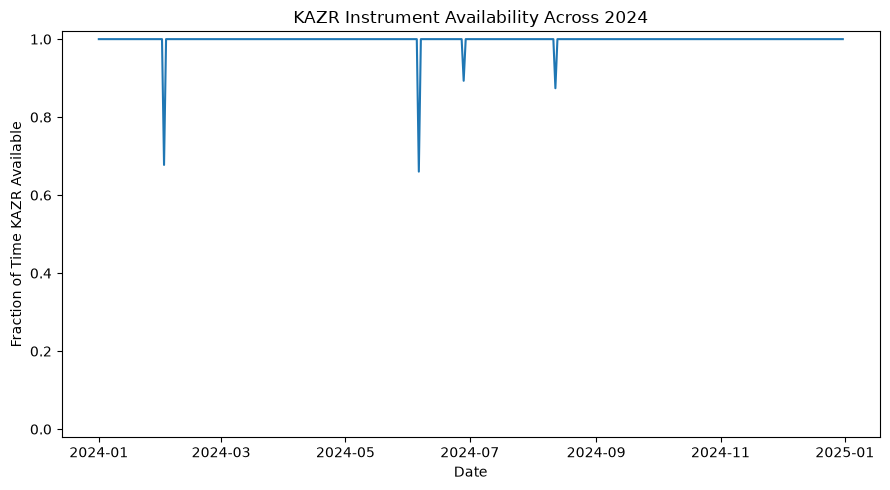

In [37]:
# Plot the fraction of time the KAZR instrument was available across 2024
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    annual_qc_df["date"],
    annual_qc_df["kazr_available_fraction"],
)
ax.set_xlabel("Date")
ax.set_ylabel("Fraction of Time KAZR Available")
ax.set_ylim(-0.02, 1.02)
ax.set_title("KAZR Instrument Availability Across 2024")
plt.tight_layout()
plt.show()

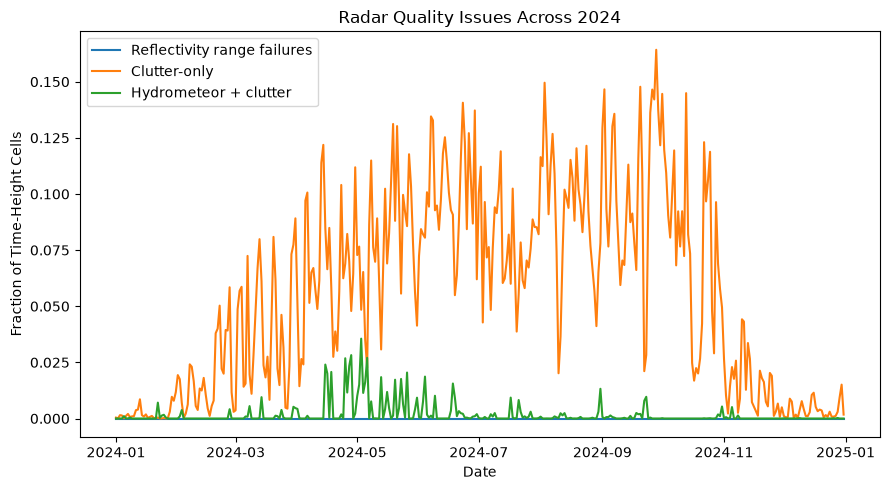

In [38]:
# Plot the fraction of time various radar quality issues occurred across 2024
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    annual_qc_df["date"],
    annual_qc_df["reflectivity_range_failure_fraction"],
    label="Reflectivity range failures",
)
ax.plot(
    annual_qc_df["date"],
    annual_qc_df["clutter_only_fraction"],
    label="Clutter-only",
)
ax.plot(
    annual_qc_df["date"],
    annual_qc_df["mixed_clutter_fraction"],
    label="Hydrometeor + clutter",
)
ax.set_xlabel("Date")
ax.set_ylabel("Fraction of Time-Height Cells")
ax.set_title("Radar Quality Issues Across 2024")
ax.legend()
plt.tight_layout()
plt.show()

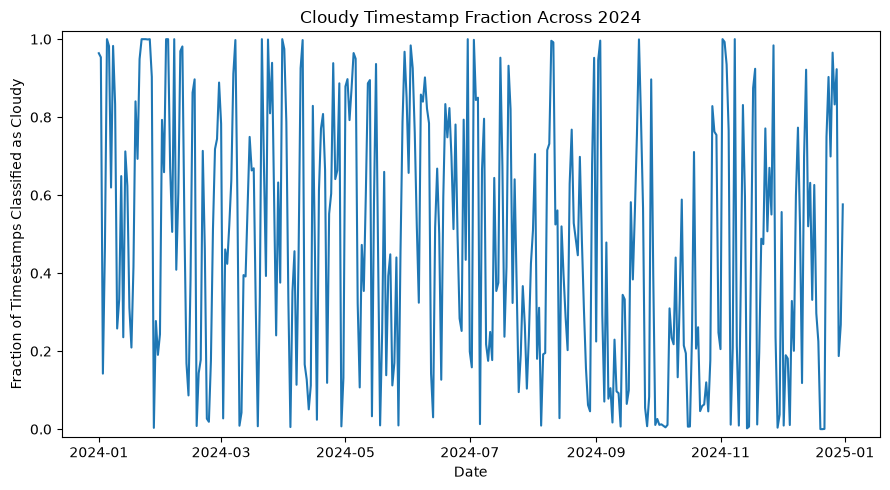

In [39]:
# Plot the fraction of timestamps classified as cloudy across 2024
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    annual_qc_df["date"],
    annual_qc_df["cloudy_timestamp_fraction"],
)
ax.set_xlabel("Date")
ax.set_ylabel("Fraction of Timestamps Classified as Cloudy")
ax.set_ylim(-0.02, 1.02)
ax.set_title("Cloudy Timestamp Fraction Across 2024")
plt.tight_layout()
plt.show()

In [40]:
print("Days with KAZR availability below 100%:")
display(
    annual_qc_df[
        annual_qc_df["kazr_available_fraction"] < 1
    ][
        [
            "date",
            "kazr_available_fraction",
            "n_time_gaps_gt_4s",
            "max_timestep_seconds",
        ]
    ].head(50)
)

print("\nDays with any reflectivity range failures:")
display(
    annual_qc_df[
        annual_qc_df["reflectivity_range_failure_fraction"] > 0
    ][
        [
            "date",
            "reflectivity_range_failure_fraction",
        ]
    ].head(50)
)

print("\nDays with clutter-only detections:")
display(
    annual_qc_df[
        annual_qc_df["clutter_only_fraction"] > 0
    ][
        [
            "date",
            "clutter_only_fraction",
        ]
    ].head(50)
)

Days with KAZR availability below 100%:


,date,kazr_available_fraction,n_time_gaps_gt_4s,max_timestep_seconds
32,2024-02-02,0.677454,0,4.0
157,2024-06-06,0.660278,0,4.0
179,2024-06-28,0.893194,0,4.0
224,2024-08-12,0.874120,0,4.0



Days with any reflectivity range failures:


,date,reflectivity_range_failure_fraction



Days with clutter-only detections:


,date,clutter_only_fraction
0,2024-01-01,0.000410
1,2024-01-02,0.000062
2,2024-01-03,0.001489
3,2024-01-04,0.001345
4,2024-01-05,0.000056
5,2024-01-06,0.001158
6,2024-01-07,0.002043
7,2024-01-08,0.000653
8,2024-01-09,0.000942
9,2024-01-10,0.001061


### Annual QC Summary
1. Firstly, we can not that the time axis is exceptionally clean, with all 366 days in 2024 present, with exactly 21,600 timestamps per day. There are zero gaps longer than 4 seconds on any day. 

2. KAZR was available almost all the time, except for four partial-availability days. These availability reductions occur without corresponding gaps in the timestamp sequence. For modeling, perhaps flagging or excluding periods where KAZR availability is false may be considered. 

3. Across 2024, Reflectivity is marked missing in 93.30% of time-height cells, Doppler velocity is marked missing in 87.70%, and Spectral width is also marked missing in 87.70%. Considering what this actually means, the radar just doesn't have a meaningful return at most height levels. The variation in these fields is also substantial, implying radar measurement availability may depend strongly on the atmospheric conditions being observed. Therefore **Radar measurement missingness needs to be handled at the individual time-height level**. 

4. There are essentially no range-based QC failures, meaning none of the measurements in 2024 were rejected because they fell outside their respective ranges. 

5. The relationship between Doppler, reflectivity, and clutter becomes clearer annually. The mean clutter-only fraction is 5.60% of all time-height cells, with a maximum daily value of about 16.4%. The annual plot also shows that clutter increases substantially though much of the spring and summer. Thus, clutter is not merely a tiny edge case that can be ignored. 

6. Lastly, cloudiness has exactly the kind of variability for prediction. Ageraged over the year, roughly 48% of timestamps are classified as cloudy, but individual day range from completely clear to completely cloudy.

### Established Conclusions
**The time axis is reliable**.
There are 366 complete days, all sampled regularly at 4 seconds, with no gaps. 

**Instrument availability is generally good**. 
Only four days have substantial KAZR downtime, so those periods can be explicitly flagged rather than treated as ordinary observations. 

**Radar profiles are inherently sparse**. 
Most time-height cells don't contain a usable radar return. This is expected measurement sparsity, not ordinary missing data. 

**Range failures are not a significant issue in 2024**.
None were observed. 

**Clutter is significant**. 
It can account for a substantial fraction of apparent radar detections, so feature construction needs to distinguish clean hydrometeor measurements from clutter. 

**Cloud state is highly variable**.
We have a good range of clear/cloudy conditions for studying persistence. 

### Conclusions / Next Steps

The annual QC analysis shows that the 2024 KAZR dataset has a highly regular temproal structure, will all 366 expected daily files presnet, exactly 21,600 timestamps per day, and a consistent 4-second sampling inverval with no gaps greater than 4 seconds. 

KAZR availability was also high overall, although four days contained periods of reduced instrument availability that should be identified and excluded or flagged during later processing. 

Radar measurement missingness is substantial, but this primarly reflects the sparse nature of radar returns across the time-height domain rather than instrument failure. 

Clutter represents a meaningful portion of radar detections, with clutter-only classifications averaging approximately 5.6% of time-height cells and reaching substantially higher levels on some days. This demonstrates that QC-passing radar measurements should not automatically be treated as clean hydrometeor observations. 

Finally, the cloud-layer product shows substantial day-to-day variability in cloud state, with daily cloudy fractions ranging from 0 to 1 and an annual mean of approximately 0.48. Overall, the dataset provides a sufficiently complete and variable foundation for investigating short-term cloud persistence, provided that instrument avilability, radar sparsity, and clutter are explicitly handled. 

The next stage will be to implement these QC findings in the data-processing pipeline. First, periods of unavailable KAZR observations will be identified using the instrument availability flag. Radar measurements will then be masked at the individual time-height level using the QC and clutter classifications, while preserving timestamps that contain valid cloud-state information. 

Following QC, the cloud-layer variables will be used to construct the primary cloud-state indicator. The next analysis will investigate the temporal behavior or cloud state and determine an appropriate temporal aggregation and persistence horizon. From there, cloud structure and radar measurements can be transformed into time-series features and combined with lagged observations to construct the modeling dataset. 